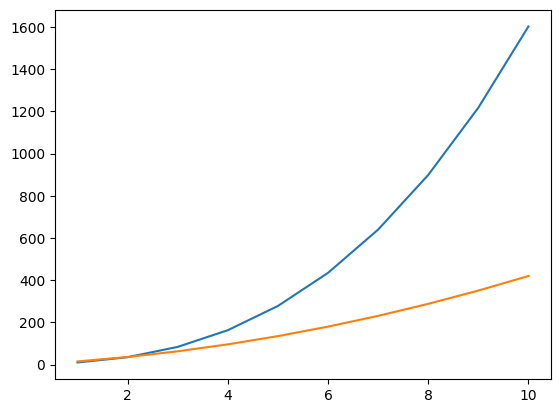

In [1]:
import matplotlib.pyplot as plt

x = [1,2,3,4,5,6,7,8,9,10]
y = [i**3+6*(i**2)+3 for i in x]
dy_dx = [3*(i**2)+12*i for i in x]
plt.plot(x,y)
plt.plot(x,dy_dx)

In [2]:
def f(x):
    return x**3+6*(x**2)+3

def df_dx(x):
    return 3*(x**2)+12*x


learning_rate = 0.01
x_current = 2
epochs = 100

x_hist = [x_current]
y_hist = [f(x_current)]

for epoch in range(epochs):
    gradient = df_dx(x_current)

    x_current = x_current - (learning_rate*gradient)

    x_hist.append(x_current)
    y_hist.append(f(x_current))

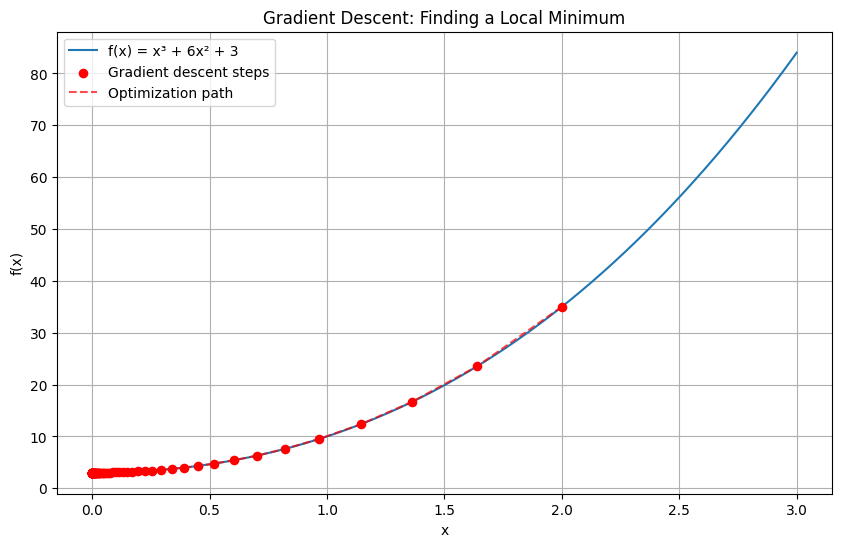

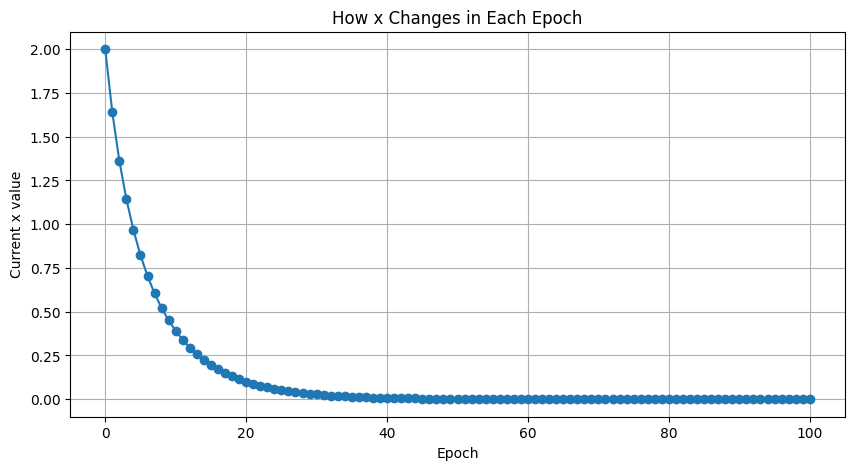

In [3]:
import numpy as np
x = np.linspace(0, 3, 500)
y = f(x)

# Plot the function and optimization path
plt.figure(figsize=(10, 6))
plt.plot(x, y, label="f(x) = x³ + 6x² + 3")

plt.scatter(
    x_hist,
    y_hist,
    color="red",
    s=35,
    label="Gradient descent steps",
    zorder=3
)

plt.plot(
    x_hist,
    y_hist,
    "r--",
    alpha=0.7,
    label="Optimization path"
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gradient Descent: Finding a Local Minimum")
plt.grid(True)
plt.legend()
plt.show()

# Plot convergence across epochs
plt.figure(figsize=(10, 5))
plt.plot(range(len(x_hist)), x_hist, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Current x value")
plt.title("How x Changes in Each Epoch")
plt.grid(True)
plt.show()

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Objective function
def f(x):
    return x[0]**2 + 4*x[1]**2

# Gradient vector
def gradient(x):
    return np.array([
        2*x[0],
        8*x[1]
    ])

# Hessian matrix
def hessian(x):
    return np.array([
        [2, 0],
        [0, 8]
    ])

# Common initial point
x0 = np.array([4.0, 3.0])

learning_rate = 0.1
epochs = 30
tolerance = 1e-10

In [5]:
# -------------------------
# Gradient Descent
# -------------------------
x_gd = x0.copy()
gd_path = [x_gd.copy()]
gd_values = [f(x_gd)]

for k in range(epochs):
    g = gradient(x_gd)

    x_gd = x_gd - learning_rate * g

    gd_path.append(x_gd.copy())
    gd_values.append(f(x_gd))

    if np.linalg.norm(gradient(x_gd)) < tolerance:
        break

In [6]:
# -------------------------
# Newton's Method
# -------------------------
x_newton = x0.copy()
newton_path = [x_newton.copy()]
newton_values = [f(x_newton)]

for k in range(epochs):
    g = gradient(x_newton)
    H = hessian(x_newton)

    # Solve H * step = gradient
    step = np.linalg.solve(H, g)
    x_newton = x_newton - step

    newton_path.append(x_newton.copy())
    newton_values.append(f(x_newton))

    if np.linalg.norm(gradient(x_newton)) < tolerance:
        break

gd_path = np.array(gd_path)
newton_path = np.array(newton_path)

In [7]:
print("Gradient Descent")
print("Iterations:", len(gd_path) - 1)
print("Minimum point:", gd_path[-1])
print("Minimum value:", f(gd_path[-1]))

print("\nNewton's Method")
print("Iterations:", len(newton_path) - 1)
print("Minimum point:", newton_path[-1])
print("Minimum value:", f(newton_path[-1]))

Gradient Descent
Iterations: 30
Minimum point: [4.95176016e-03 3.22122547e-21]
Minimum value: 2.4519928653854235e-05

Newton's Method
Iterations: 1
Minimum point: [0. 0.]
Minimum value: 0.0


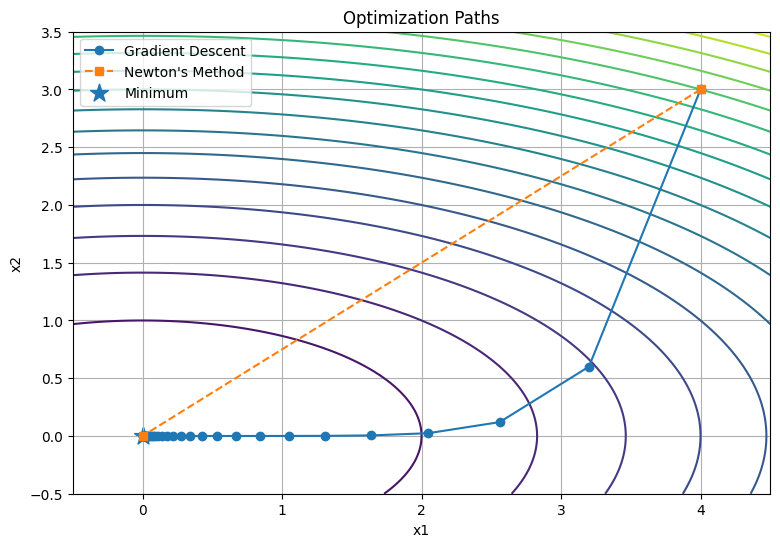

In [8]:
# -------------------------
# Plot 1: Contour and paths
# -------------------------
a = np.linspace(-0.5, 4.5, 200)
b = np.linspace(-0.5, 3.5, 200)
X1, X2 = np.meshgrid(a, b)
Z = X1**2 + 4*X2**2

plt.figure(figsize=(9, 6))
plt.contour(X1, X2, Z, levels=20)

plt.plot(
    gd_path[:, 0], gd_path[:, 1],
    "o-", label="Gradient Descent"
)

plt.plot(
    newton_path[:, 0], newton_path[:, 1],
    "s--", label="Newton's Method"
)

plt.scatter(0, 0, marker="*", s=180, label="Minimum")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Optimization Paths")
plt.legend()
plt.grid(True)
plt.show()

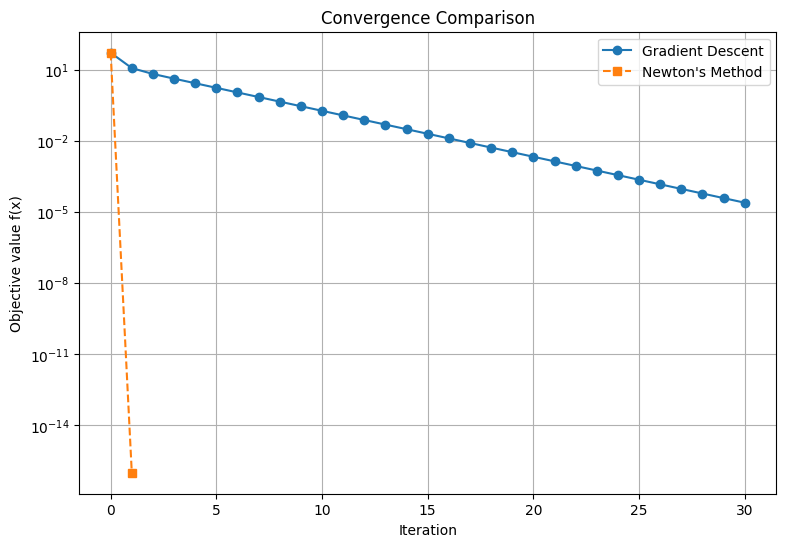

In [9]:
# -------------------------
# Plot 2: Convergence
# -------------------------
plt.figure(figsize=(9, 6))

plt.semilogy(
    range(len(gd_values)),
    np.maximum(gd_values, 1e-16),
    "o-", label="Gradient Descent"
)

plt.semilogy(
    range(len(newton_values)),
    np.maximum(newton_values, 1e-16),
    "s--", label="Newton's Method"
)

plt.xlabel("Iteration")
plt.ylabel("Objective value f(x)")
plt.title("Convergence Comparison")
plt.legend()
plt.grid(True)
plt.show()


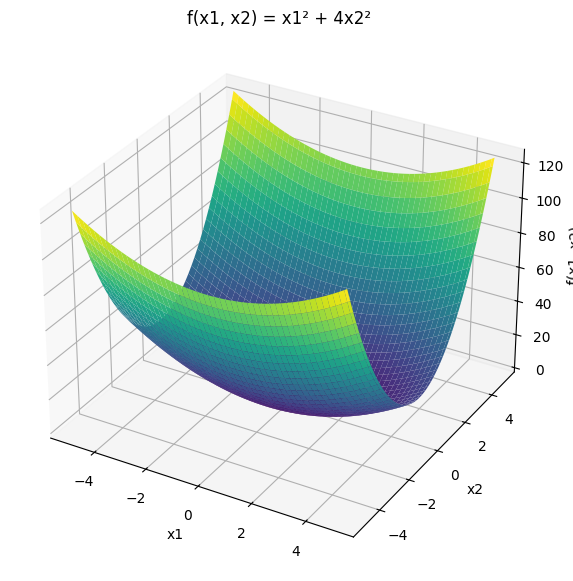

In [10]:

import numpy as np
import matplotlib.pyplot as plt

# Define the range of x1 and x2
x1 = np.linspace(-5, 5, 100)
x2 = np.linspace(-5, 5, 100)

# Create a grid of points
X1, X2 = np.meshgrid(x1, x2)

# Calculate the function value at every point
Z = X1**2 + 4 * X2**2

# Plot the 3D surface
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(X1, X2, Z, cmap="viridis", edgecolor="none")

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("f(x1, x2)")
ax.set_title("f(x1, x2) = x1² + 4x2²")

plt.show()


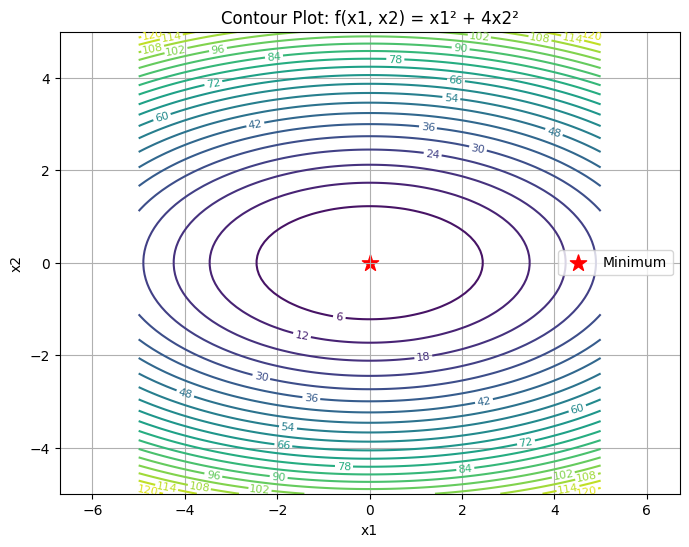

In [11]:

plt.figure(figsize=(8, 6))

contours = plt.contour(X1, X2, Z, levels=20)
plt.clabel(contours, inline=True, fontsize=8)

plt.scatter(0, 0, color="red", marker="*", s=150, label="Minimum")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Contour Plot: f(x1, x2) = x1² + 4x2²")
plt.legend()
plt.axis("equal")
plt.grid(True)
plt.show()
